In [16]:
import torch
from torchvision import datasets, transforms
from models.nn import *
import matplotlib.pyplot as plt
from models.utils import *
from models.bmi import *
from models.aemi import *

In [2]:
img_size = 32
test_labels = 10
# set the random seed
torch.manual_seed(0)
np.random.seed(0)

In [3]:
# load the data
transform = transforms.Compose([
    transforms.Resize(img_size),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# load mnist
train_dataset = datasets.MNIST('../data/', train=True, download=True, transform=transform)

In [4]:
grouped_data = {label: [] for label in range(10)}
train_loaders = []

# group the data
for data in train_dataset:
    label = data[1]
    grouped_data[label].append(data)

class_batch_size = 100
for c in range(test_labels):
    train_loaders.append(torch.utils.data.DataLoader(grouped_data[c], batch_size=class_batch_size, shuffle=True))

# construct the train dataset: X, Y are i.i.d. samples from the same class
X = []
Y = []
for c in range(test_labels):
    # for _ in range(10):
    data1, _ = next(iter(train_loaders[c]))
    data2, _ = next(iter(train_loaders[c]))
    X.append(data1)
    Y.append(data2)

X = torch.cat(X)
Y = torch.cat(Y)
XY = torch.cat((X, Y), dim=1)

In [10]:
if torch.cuda.is_available():
    X = X.cuda()
    Y = Y.cuda()
    XY = XY.cuda()

In [6]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
ae_model = AECrossMNIST(code_dim=12).to(device)
# load the model
# ae_model.load_state_dict(torch.load('./checkpoints/aemi_demo.pt'))

In [7]:
X.shape

torch.Size([1000, 1, 32, 32])

In [11]:
train(ae_model, X, Y, batch_size=100, lr=0.0002, epochs=5000)

In [12]:
# # save model
# torch.save(ae_model.state_dict(), f'./checkpoints/aemi_mnist.pt')

In [13]:
with torch.no_grad():
    Zx = ae_model.x_encoder(X)
    Zy = ae_model.y_encoder(Y)

In [23]:
mine = MINE(12,12,64).to(device)

In [24]:
mi_est = train_estimator(mine, Zx, Zy, bs=100, lr=1e-4, iters=20000)

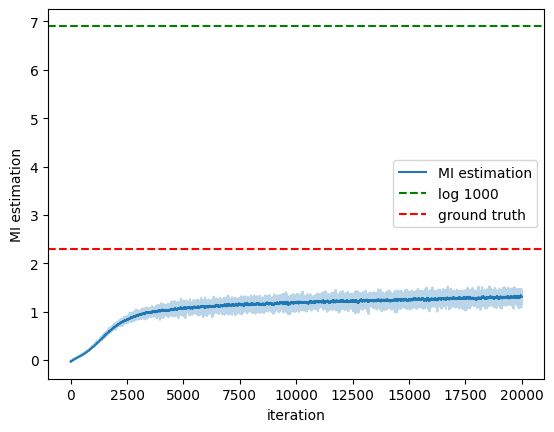

In [25]:
n_classes = 10
import pandas as pd
import math
EMA_SPAN = 50
p1 = plt.plot(mi_est, alpha=0.3)[0]
mis_smooth = pd.Series(mi_est).ewm(span=EMA_SPAN).mean()
plt.plot(mis_smooth, c=p1.get_color(), label=f'MI estimation')
plt.axhline(math.log(XY.shape[0]), c='g', ls='--', label=f'log {XY.shape[0]}')
plt.axhline(math.log(n_classes), c='r', ls='--', label='ground truth')
plt.xlabel('iteration')
plt.ylabel('MI estimation')
plt.legend()
# plt.legend(['raw', 'MI EMA'])
# plt.savefig(f'./figs/mi_est_label{test_labels}.png')
plt.show()

In [26]:
torch.save(mi_est, './mi_list/aemi_mnist.pt')